In [1]:
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torch

### Data Stuff

In [2]:
words = open('../names.txt', 'r').read().splitlines()

In [3]:
letters = sorted(list(set(''.join(words))))
str_to_int = {s:i+1 for i, s in enumerate(letters)}
str_to_int['.'] = 0
int_to_str = {i:s for s, i in str_to_int.items()}
vocab_size = len(int_to_str)

In [4]:
def build_dataset(words):
    context_length = 8
    X, Y = [], []

    for word in words:
        context = [0] * context_length
        for character in word + '.':
            index = str_to_int[character]
            Y.append(index)
            X.append(context)
            context = context[1:] + [index]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(1234)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtrain, Ytrain = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[n2:])

In [5]:
for x, y in zip(Xtrain[:20], Ytrain[:20]):
    print(''.join(int_to_str[index.item()] for index in x), '--->', int_to_str[y.item()])

........ ---> c
.......c ---> o
......co ---> n
.....con ---> n
....conn ---> e
...conne ---> l
..connel ---> l
.connell ---> y
connelly ---> .
........ ---> a
.......a ---> u
......au ---> l
.....aul ---> d
....auld ---> e
...aulde ---> n
..aulden ---> .
........ ---> a
.......a ---> s
......as ---> h
.....ash ---> a


### Classes

In [6]:
embedded_dim = 10
n_hidden = 200
context_length = 8

g = torch.Generator().manual_seed(6710)
C = torch.randn((vocab_size,embedded_dim),                  generator=g)
W1 = torch.randn((context_length * embedded_dim, n_hidden), generator=g) * (5/3) / (context_length * embedded_dim)**0.5
W2 = torch.randn((n_hidden, vocab_size),                    generator=g) * 0.01
b2 = torch.rand(27,                                         generator=g) * 0
bn_gain = torch.ones(1, n_hidden)
bn_bias = torch.zeros(1, n_hidden)

bn_mean_running = torch.zeros(1, n_hidden)
bn_std_running = torch.ones(1, n_hidden)

parameters = [C, W1, W2, b2, bn_gain, bn_bias]

for p in parameters:
    p.requires_grad=True

In [7]:
class Linear:
    def __init__(self, n_inputs, n_outputs, bias = False):
        self.weights = torch.randn(n_inputs, n_outputs) * (1 / n_inputs**0.5)
        self.bias = torch.zeros(n_outputs) if bias else None

    def __call__(self, x):
        self.out = x @ self.weights 
        if self.bias is not None:
            self.out += self.bias 
        return self.out

    def parameters(self):
        return [self.weights] + ([self.bias] if self.bias is not None else [])

In [8]:
class Batch_Normalisation:
    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training  = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

        self.running_mean = torch.zeros(dim) 
        self.running_std = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            if x.dim() == 2:
                dim = 0
            elif x.dim() == 3:
                dim = (0,1)

            current_mean = x.mean(dim,keepdim = True)
            current_std = x.std(dim, keepdim = True)

            with torch.no_grad():
                self.running_mean = (1-self.momentum) * self.running_mean + self.momentum * current_mean
                self.running_std = (1-self.momentum) * self.running_std + self.momentum * current_std

        if self.training:
            x_pre_act = (x - current_mean)/ (current_std + self.eps)
        else:
            x_pre_act = (x - self.running_mean)/ (self.running_std  + self.eps)

        self.out = self.gamma * x_pre_act + self.beta
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

In [9]:
class tanh:    
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

In [10]:
class Embedding:
    def __init__(self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim))

    def __call__(self, index):
        self.out = self.weight[index]
        return self.out


    def parameters(self):
        return [self.weight]

In [11]:
class Flatten_Consecutive:
    def __init__(self, n):
          self.n = n


    def __call__(self, x):
            B, T, C = x.shape
            x = x.view(B, -1, C*self.n)
            if x.shape[1] ==1:
                x = x.squeeze(1)
            self.out = x
            return self.out

    def parameters(self):
          return []

In [12]:
class Sequential():
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
        


### MLP

In [13]:
context_length = 8
vocab_size = 27
emb_size = 10
n_hidden = 200
g = torch.Generator().manual_seed(67676767)


model = Sequential([
    Embedding(vocab_size, emb_size),
    Flatten_Consecutive(2), Linear(n_inputs = 2 * emb_size, n_outputs = n_hidden, bias = False), Batch_Normalisation(n_hidden), tanh(),
    Flatten_Consecutive(2), Linear(n_inputs = 2 * n_hidden, n_outputs = n_hidden, bias = False), Batch_Normalisation(n_hidden), tanh(),
    Flatten_Consecutive(2), Linear(n_inputs = 2 * n_hidden, n_outputs = n_hidden, bias = False), Batch_Normalisation(n_hidden), tanh(),
    Linear(n_inputs = n_hidden, n_outputs = vocab_size, bias = True),
])

with torch.no_grad():
    model.layers[-1].weights *= 0.1  # less confident last layer

parameters = model.parameters()
for p in parameters:
    p.requires_grad = True

In [14]:
max_steps = 200_000
batch_size = 32
loss_list = []


for k in range(max_steps):

    #minibatch
    index = torch.randint(0, Xtrain.shape[0], (batch_size,) , generator=g)
    #Xb, Yb = Xtrain[index], Ytrain[index]

    # Forward
    logits = model(Xtrain[index])
    loss = F.cross_entropy(logits, Ytrain[index])


    #Backward
    for p in parameters:
        p.grad = None
    loss.backward()

    #Update
    step_size = 0.1 if k < 100_000 else 0.01
    for p in parameters:
        p.data += -step_size * p.grad

    #tracking
    if k % 10_000 == 0:
        print(f"{k:7d}/{max_steps:7d}: {loss.item():.4f}")
    loss_list.append(loss.log10().item())


      0/ 200000: 3.2937
  10000/ 200000: 2.1405
  20000/ 200000: 2.0658
  30000/ 200000: 1.9184
  40000/ 200000: 1.7534
  50000/ 200000: 2.0798
  60000/ 200000: 1.9614
  70000/ 200000: 1.9223
  80000/ 200000: 2.3182
  90000/ 200000: 1.5797
 100000/ 200000: 1.8786
 110000/ 200000: 1.9512
 120000/ 200000: 1.8001
 130000/ 200000: 1.8885
 140000/ 200000: 1.5039
 150000/ 200000: 1.6406
 160000/ 200000: 1.6280
 170000/ 200000: 1.9583
 180000/ 200000: 2.0941
 190000/ 200000: 1.4554


#### plot the loss (will be hella thick cus high var for batch)

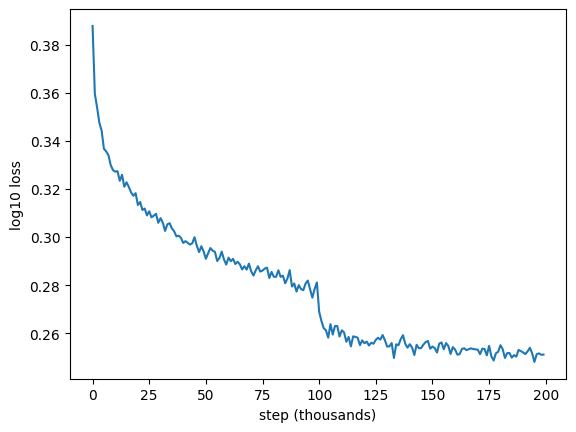

In [20]:
plt.plot(torch.tensor(loss_list).view(-1, 1000).mean(1))
plt.xlabel('step (thousands)'); plt.ylabel('log10 loss');

### Evaluate Loss

In [16]:
#now in evaluation stage (needde especially for batchnorm)
for layer in model.layers:
    layer.training = False

In [17]:
@torch.no_grad() #cus only evaluating loss dont need gradients, waste of memory and time
def split_loss(split):
    x,y = {
        'train': (Xtrain, Ytrain),
        'evaluate': (Xval, Yval),
        'test' : (Xtest, Ytest)
    }[split]

    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('evaluate')

train 1.761183261871338
evaluate 1.9845194816589355


### sample from the model

In [22]:
for layer in model.layers:
    layer.training = False

g = torch.Generator().manual_seed(6710 + 10)

for i in range(10):
    out = []
    context = [0] * context_length
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1)
        index = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [index]
        out.append(index)
        if index == 0:
            break
    print(''.join(int_to_str[i] for i in out))

teyas.
kaisley.
evalyn.
abdulbertu.
skylliegha.
marvius.
amik.
aryiah.
dmorie.
paitlyn.
